## Library Setup for KMeans Clustering

This section imports the required libraries for building a clustering-based recommendation system using KMeans.

---

### Libraries Used

- Data handling and manipulation for structured datasets  
- Numerical computation for efficient array operations  
- Parsing utilities for handling structured string data  
- Text processing for normalization and cleaning  

---

### Machine Learning Components

- Feature scaling to normalize input data  
- Multi-label encoding for transforming genre data into numerical form  
- KMeans clustering for grouping similar songs  

---

### Purpose

- Prepares the environment for clustering-based recommendation  
- Enables grouping of songs into similarity-based clusters  
- Supports feature engineering and preprocessing required for clustering  

In [1]:
import pandas as pd
import numpy as np
import ast
import re

from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans

## Data Preparation for KMeans Model

This section prepares the dataset for use in the clustering-based recommendation model.

---

### Data Loading

- Loads the final dataset containing songs and cleaned genre information  
- Serves as the input for clustering and similarity grouping  

---

### Artist Formatting

- Ensures that the artist field is consistently represented as a list  
- Converts string representations into structured lists when necessary  
- Handles parsing errors gracefully  

---

### Text Normalization

- Creates a cleaned version of track names  
- Removes extra whitespace and standardizes casing  
- Enables consistent identification of songs  

---

### Purpose

- Ensures uniform and reliable data structure  
- Prepares clean inputs for clustering algorithms  
- Reduces inconsistencies that may affect grouping quality  

In [2]:
df = pd.read_csv("songs_with_genres_final.csv")

def ensure_list(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return x

df['artists'] = df['artists'].apply(ensure_list)
df['name_clean'] = df['name'].str.strip().str.lower()

## Genre Feature Encoding for Clustering

This section converts genre data into numerical features for use in the KMeans clustering model.

---

### Genre List Preparation

- Transforms genre strings into lists of individual genre labels  
- Removes empty entries and extra whitespace  
- Ensures a structured representation of genres for each track  

---

### Multi-Label Encoding

- Converts genre lists into binary feature vectors  
- Each unique genre becomes a separate column  
- Indicates whether a track belongs to each genre  

---

### Feature Weighting

- Applies a scaling factor to genre features  
- Controls their influence relative to other features  

---

### Data Integration

- Appends the generated genre features to the original dataset  
- Creates a unified dataset containing all relevant attributes  

---

### Output Insight

- Displays the total number of genre-based features  
- Provides an overview of the feature space expansion  

---

### Purpose

- Transforms categorical genre data into a machine-readable format  
- Enables clustering algorithms to group songs based on genre similarity  
- Enhances the representation of songs for better clustering performance  

In [3]:
df['genre_list'] = df['genres_filtered'].fillna('').apply(
    lambda x: [g.strip() for g in x.split(',') if g]
)

mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(df['genre_list'])

genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_) * 0.5

df = pd.concat([df, genre_df], axis=1)

print("Genre features:", len(genre_df.columns))

Genre features: 597


## Feature Construction and Scaling for Clustering

This section prepares the feature matrix used for KMeans clustering.

---

### Feature Composition

- Combines:
  - Audio features such as danceability, energy, tempo, and others  
  - Genre-based features obtained from multi-label encoding  

---

### Handling Missing Values

- Replaces missing values with zero  
- Ensures a complete and consistent dataset  

---

### Feature Scaling

- Applies standardization to normalize all features  
- Transforms features to have zero mean and unit variance  
- Prevents certain features from dominating clustering due to scale differences  

---

### Feature Matrix

- Constructs a numerical matrix representing each track  
- Converts data into a format suitable for clustering algorithms  

---

### Output Insight

- Displays the shape of the feature matrix  
- Indicates the number of tracks and total features used  

---

### Purpose

- Creates a balanced representation of songs  
- Combines audio and genre information  
- Prepares data for effective clustering using KMeans  

In [4]:
base_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'popularity'
]

features = base_features + list(genre_df.columns)

df[features] = df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features]).astype('float32')

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (173613, 607)


## KMeans Clustering

This section applies KMeans clustering to group similar songs based on their feature representations.

---

### Cluster Configuration

- Defines the number of clusters used to group songs  
- Sets a fixed random state for reproducibility  
- Uses multiple initializations to improve clustering stability  

---

### Model Training

- Applies the KMeans algorithm to the scaled feature matrix  
- Assigns each song to a cluster based on similarity  

---

### Cluster Assignment

- Stores the cluster label for each song in the dataset  
- Each cluster represents a group of similar songs  

---

### Output

- Confirms completion of the clustering process  

---

### Purpose

- Groups songs into similarity-based clusters  
- Enables fast retrieval of similar songs within the same cluster  
- Serves as an alternative approach to distance-based recommendation methods  

In [5]:
k = 50  

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df = df.copy()

df['cluster'] = kmeans.fit_predict(X_scaled)

print("KMeans clustering done")

KMeans clustering done


## KMeans-Based Recommendation Function

This section implements a recommendation system using cluster-based similarity.

---

### Input Handling

- Accepts a song name and an optional artist name  
- Normalizes the input for consistent matching  
- Filters the dataset to locate the correct song  
- If multiple matches exist, selects the most popular one  

---

### Cluster Identification

- Determines the cluster assigned to the input song  
- Uses this cluster as the search space for recommendations  

---

### Candidate Selection

- Retrieves all songs belonging to the same cluster  
- Excludes the input song from the candidate list  

---

### Deduplication

- Removes duplicate entries based on song name and artist  
- Ensures unique recommendations  

---

### Artist Diversity Control

- Limits the number of recommendations per artist  
- Prevents overrepresentation of a single artist  
- Maintains diversity within results  

---

### Result Selection

- Iterates through cluster members  
- Selects the top results based on the requested number  

---

### Output

- Returns structured recommendations including:
  - Song name  
  - Artists  
  - Genres  
  - Popularity  

---

### Purpose

- Provides a fast recommendation method using clustering  
- Groups similar songs into clusters for efficient retrieval  
- Offers an alternative to distance-based similarity approaches  

In [21]:
from collections import defaultdict

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None

def recommend_kmeans(song_name, artist_name=None, n=5):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return []

    idx = matches.sort_values(by='popularity', ascending=False).index[0]

    cluster_id = df.loc[idx, 'cluster']

    cluster_songs = df[df['cluster'] == cluster_id]

    # remove itself
    cluster_songs = cluster_songs.drop(index=idx)

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in cluster_songs.index:
        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        if key in seen_tracks:
            continue

        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1

        results.append({
            "name": df.loc[i, 'name'],
            "artists": df.loc[i, 'artists'],
            "genres": df.loc[i, 'genres_filtered'],
            "popularity": df.loc[i, 'popularity']
        })

        if len(results) >= n:
            break

    return results

In [22]:
recs = recommend_kmeans("DNA.", "Kendrick Lamar", 5)

for i, song in enumerate(recs, 1):
    print(f"Recommendation {i}")
    print(f"Name       : {song['name']}")
    print(f"Artists    : {', '.join(song['artists'])}")
    print(f"Genres     : {song['genres']}")
    print(f"Popularity : {song['popularity']}")
    print("-" * 50)

Recommendation 1
Name       : Can't Take My Eyes off You
Artists    : Frankie Valli
Genres     : easy listening, love, oldies, romantic
Popularity : 69
--------------------------------------------------
Recommendation 2
Name       : I Want You Back
Artists    : The Jackson 5
Genres     : disco, funk, motown, oldies, pop, soul
Popularity : 76
--------------------------------------------------
Recommendation 3
Name       : I'm Not In Love
Artists    : 10cc
Genres     : classic rock, love, oldies, pop, rock, romantic, soft rock
Popularity : 70
--------------------------------------------------
Recommendation 4
Name       : Hotel California - 2013 Remaster
Artists    : Eagles
Genres     : country rock, pop, pop rock, reggae, rock, sad, soft rock, vocal
Popularity : 83
--------------------------------------------------
Recommendation 5
Name       : Dancing Queen
Artists    : ABBA
Genres     : dance, disco, oldies, pop, swedish
Popularity : 78
------------------------------------------------

### GRAPHS AND ANALYSIS  
Here we have analyzed our recommnedations by comparing them against the input song like a line plot, radar comparison, heatmap etc.

In [15]:
def get_song_index(song_name, artist_name=None):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return None

    # pick most popular if multiple matches
    idx = matches.sort_values(by='popularity', ascending=False).index[0]
    return idx

In [7]:
from collections import defaultdict
import re

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None


def recommend_kmeans_idx(idx, k=5):

    cluster_id = df.loc[idx, 'cluster']
    cluster_songs = df[df['cluster'] == cluster_id]

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in cluster_songs.index:

        if i == idx:
            continue

        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        # remove duplicates
        if key in seen_tracks:
            continue

        # limit same artist
        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        results.append(i)

        if len(results) >= k:
            break

    # fallback if not enough
    if len(results) < k:
        for i in cluster_songs.index:
            if i == idx:
                continue
            if i not in results:
                results.append(i)
            if len(results) >= k:
                break

    return results

In [8]:
def recommend_kmeans_by_name(song_name, artist_name=None, k=5):

    idx = get_song_index(song_name, artist_name)
    if idx is None:
        return None, []

    recs = recommend_kmeans_idx(idx, k)
    return idx, recs

In [9]:
def compare_features_scaled(input_idx, rec_indices):

    feature_names = base_features
    feature_indices = list(range(len(base_features)))  # audio features only

    plt.figure(figsize=(10, 5))

    # Input song
    input_vals = X_scaled[input_idx, feature_indices]
    plt.plot(feature_names, input_vals, marker='o', linewidth=2, label='Input')

    # Recommendations
    for i, idx in enumerate(rec_indices):
        rec_vals = X_scaled[idx, feature_indices]
        plt.plot(feature_names, rec_vals, marker='o', alpha=0.7, label=f'Rec {i+1}')

    plt.xticks(rotation=45)
    plt.title("Scaled Audio Feature Comparison")
    plt.legend()
    plt.show()

In [10]:
def heatmap_compare_scaled(input_idx, rec_indices):

    indices = [input_idx] + list(rec_indices)
    labels = ["Input"] + [f"Rec {i+1}" for i in range(len(rec_indices))]

    feature_indices = list(range(len(base_features)))
    data = X_scaled[indices][:, feature_indices]

    plt.figure(figsize=(8, 4))
    sns.heatmap(
        data,
        yticklabels=labels,
        xticklabels=base_features,
        cmap="coolwarm"
    )

    plt.title("Scaled Feature Heatmap")
    plt.show()

In [12]:
def radar_compare_scaled(input_idx, rec_indices):

    features_to_plot = base_features[:6]  # keep readable
    feature_indices = [base_features.index(f) for f in features_to_plot]

    angles = np.linspace(0, 2*np.pi, len(features_to_plot), endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6,6))

    # Input
    input_vals = X_scaled[input_idx, feature_indices].tolist()
    input_vals += input_vals[:1]

    plt.plot(angles, input_vals, linewidth=2, label="Input")
    plt.fill(angles, input_vals, alpha=0.25)

    # Recommendations
    for i, idx in enumerate(rec_indices):
        vals = X_scaled[idx, feature_indices].tolist()
        vals += vals[:1]

        plt.plot(angles, vals, linewidth=1.5, alpha=0.8, label=f"Rec {i+1}")
        plt.fill(angles, vals, alpha=0.1)

    plt.xticks(angles[:-1], features_to_plot)
    plt.title("Scaled Radar Comparison")
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()

### Genre comparison and Jaccard similarity  
In this we have taken the input song and compared the common genres with our recommended songs to analyse the affect of genres in our engine  
We have used a Jaccard Score which divides the No. of common genres by No. of total unique genres between the both of them

In [13]:
def compare_genres(input_idx, rec_indices):

    input_name = df.loc[input_idx, 'name']
    input_artist = ", ".join(df.loc[input_idx, 'artists'])
    input_genres = set(df.loc[input_idx, 'genre_list'])

    print("INPUT SONG")
    print(f"Name   : {input_name}")
    print(f"Artist : {input_artist}")
    print(f"Genres : {', '.join(input_genres)}")
    print("-" * 50)

    for i, idx in enumerate(rec_indices):

        rec_name = df.loc[idx, 'name']
        rec_artist = ", ".join(df.loc[idx, 'artists'])
        rec_genres = set(df.loc[idx, 'genre_list'])

        overlap = input_genres & rec_genres
        union = input_genres | rec_genres

        similarity = len(overlap) / len(union) if union else 0

        print(f"\nRecommendation {i+1}")
        print(f"Name       : {rec_name}")
        print(f"Artists    : {rec_artist}")
        print(f"Genres     : {', '.join(rec_genres)}")
        print(f"Common     : {', '.join(overlap) if overlap else 'None'}")
        print(f"Jaccard    : {round(similarity, 3)}")
        print("-" * 50)

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### SHORTCOMINGS OF KMEANS  
## KMeans while showing a good performance in terms of audio features falls short in terms of genres
While the radar comparison shows good overlapping with the input song the jaccard score for all our generated outcomes is 0 meaning that none of the genres matched

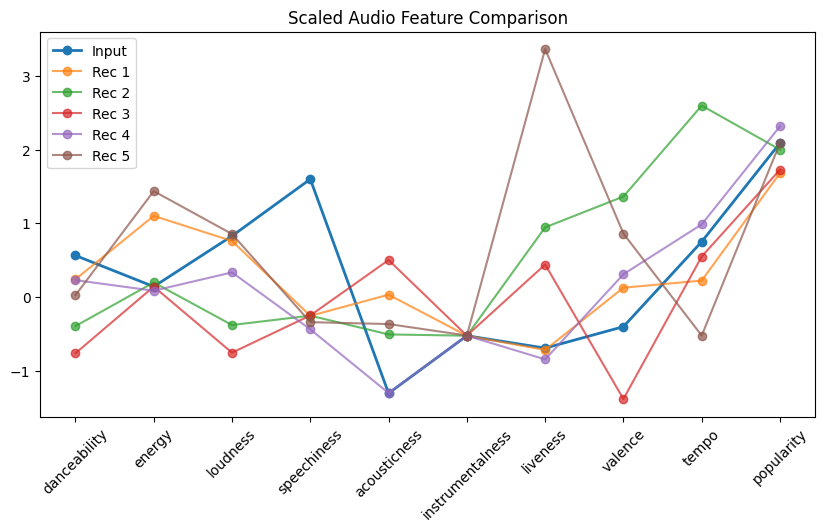

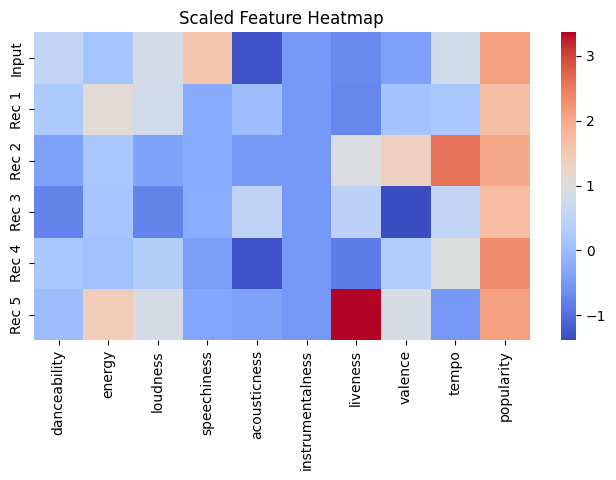

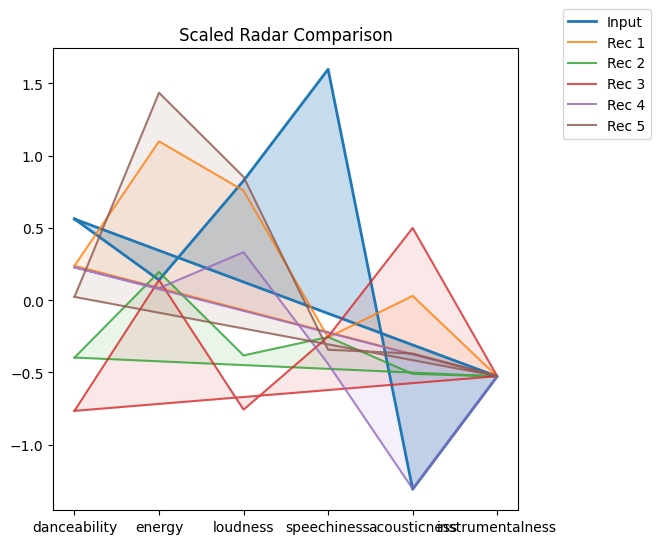

INPUT SONG
Name   : DNA.
Artist : Kendrick Lamar
Genres : trap, hip hop, west coast hip hop, conscious hip hop, hardcore hip hop, political hip hop
--------------------------------------------------

Recommendation 1
Name       : Can't Take My Eyes off You
Artists    : Frankie Valli
Genres     : oldies, romantic, easy listening, love
Common     : None
Jaccard    : 0.0
--------------------------------------------------

Recommendation 2
Name       : I Want You Back
Artists    : The Jackson 5
Genres     : oldies, funk, disco, soul, motown, pop
Common     : None
Jaccard    : 0.0
--------------------------------------------------

Recommendation 3
Name       : I'm Not In Love
Artists    : 10cc
Genres     : soft rock, oldies, love, classic rock, rock, romantic, pop
Common     : None
Jaccard    : 0.0
--------------------------------------------------

Recommendation 4
Name       : Hotel California - 2013 Remaster
Artists    : Eagles
Genres     : soft rock, pop rock, reggae, rock, sad, vocal,

In [19]:
idx, recs_km = recommend_kmeans_by_name("DNA.", "Kendrick Lamar", 5)

compare_features_scaled(idx, recs_km)
heatmap_compare_scaled(idx, recs_km)
radar_compare_scaled(idx, recs_km)
compare_genres(idx, recs_km)